In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import joblib

In [2]:
df = pd.read_csv("Beans_Multiclass_Classification_Dataset.csv")

df.head()

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRation,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272750,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER


In [3]:
df.shape


(13611, 17)

In [4]:
df.columns.tolist()

['Area',
 'Perimeter',
 'MajorAxisLength',
 'MinorAxisLength',
 'AspectRation',
 'Eccentricity',
 'ConvexArea',
 'EquivDiameter',
 'Extent',
 'Solidity',
 'roundness',
 'Compactness',
 'ShapeFactor1',
 'ShapeFactor2',
 'ShapeFactor3',
 'ShapeFactor4',
 'Class']

In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non-null  int64  
 1   Perimeter        13611 non-null  float64
 2   MajorAxisLength  13611 non-null  float64
 3   MinorAxisLength  13611 non-null  float64
 4   AspectRation     13611 non-null  float64
 5   Eccentricity     13611 non-null  float64
 6   ConvexArea       13611 non-null  int64  
 7   EquivDiameter    13611 non-null  float64
 8   Extent           13611 non-null  float64
 9   Solidity         13611 non-null  float64
 10  roundness        13611 non-null  float64
 11  Compactness      13611 non-null  float64
 12  ShapeFactor1     13611 non-null  float64
 13  ShapeFactor2     13611 non-null  float64
 14  ShapeFactor3     13611 non-null  float64
 15  ShapeFactor4     13611 non-null  float64
 16  Class            13611 non-null  str    
dtypes: float64(14), int64(2

In [6]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Area,13611.0,53048.284549,29324.095717,20420.000000,36328.000000,44652.000000,61332.000000,254616.000000
Perimeter,13611.0,855.283459,214.289696,524.736000,703.523500,794.941000,977.213000,1985.370000
MajorAxisLength,13611.0,320.141867,85.694186,183.601165,253.303633,296.883367,376.495012,738.860153
MinorAxisLength,13611.0,202.270714,44.970091,122.512653,175.848170,192.431733,217.031741,460.198497
AspectRation,13611.0,1.583242,0.246678,1.024868,1.432307,1.551124,1.707109,2.430306
Eccentricity,13611.0,0.750895,0.092002,0.218951,0.715928,0.764441,0.810466,0.911423
ConvexArea,13611.0,53768.200206,29774.915817,20684.000000,36714.500000,45178.000000,62294.000000,263261.000000
EquivDiameter,13611.0,253.064220,59.177120,161.243764,215.068003,238.438026,279.446467,569.374358
Extent,13611.0,0.749733,0.049086,0.555315,0.718634,0.759859,0.786851,0.866195
Solidity,13611.0,0.987143,0.004660,0.919246,0.985670,0.988283,0.990013,0.994677


In [7]:
df.isnull().sum()

Area               0
Perimeter          0
MajorAxisLength    0
MinorAxisLength    0
AspectRation       0
Eccentricity       0
ConvexArea         0
EquivDiameter      0
Extent             0
Solidity           0
roundness          0
Compactness        0
ShapeFactor1       0
ShapeFactor2       0
ShapeFactor3       0
ShapeFactor4       0
Class              0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(68)

In [9]:
df = df.drop_duplicates().copy()

In [10]:
df.shape

(13543, 17)

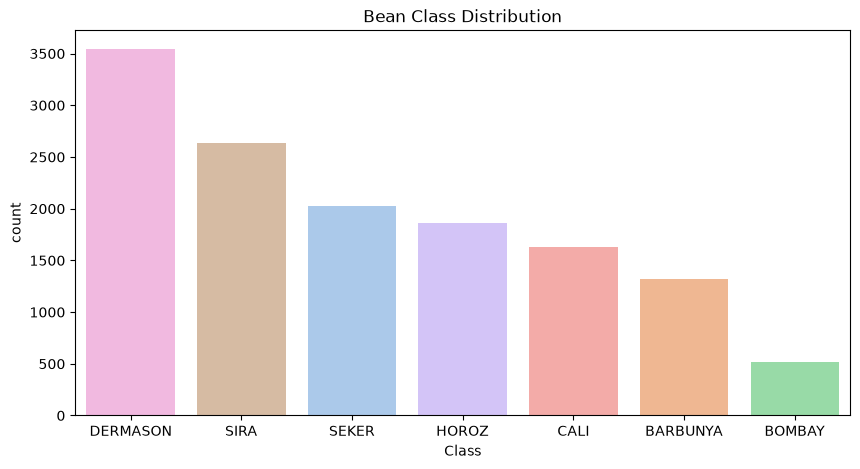

In [17]:
# # Class Distribution


# print(df["Class"].value_counts())

# plt.figure(figsize=(10, 5))
# sns.countplot(data=df, x="Class", order=df["Class"].value_counts().index,color='orange')
# plt.title("Bean Class Distribution")
# plt.show()

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Class",
    order=df["Class"].value_counts().index,
    hue="Class",            
    palette="pastel",         
    legend=False
)
plt.title("Bean Class Distribution")
plt.show()

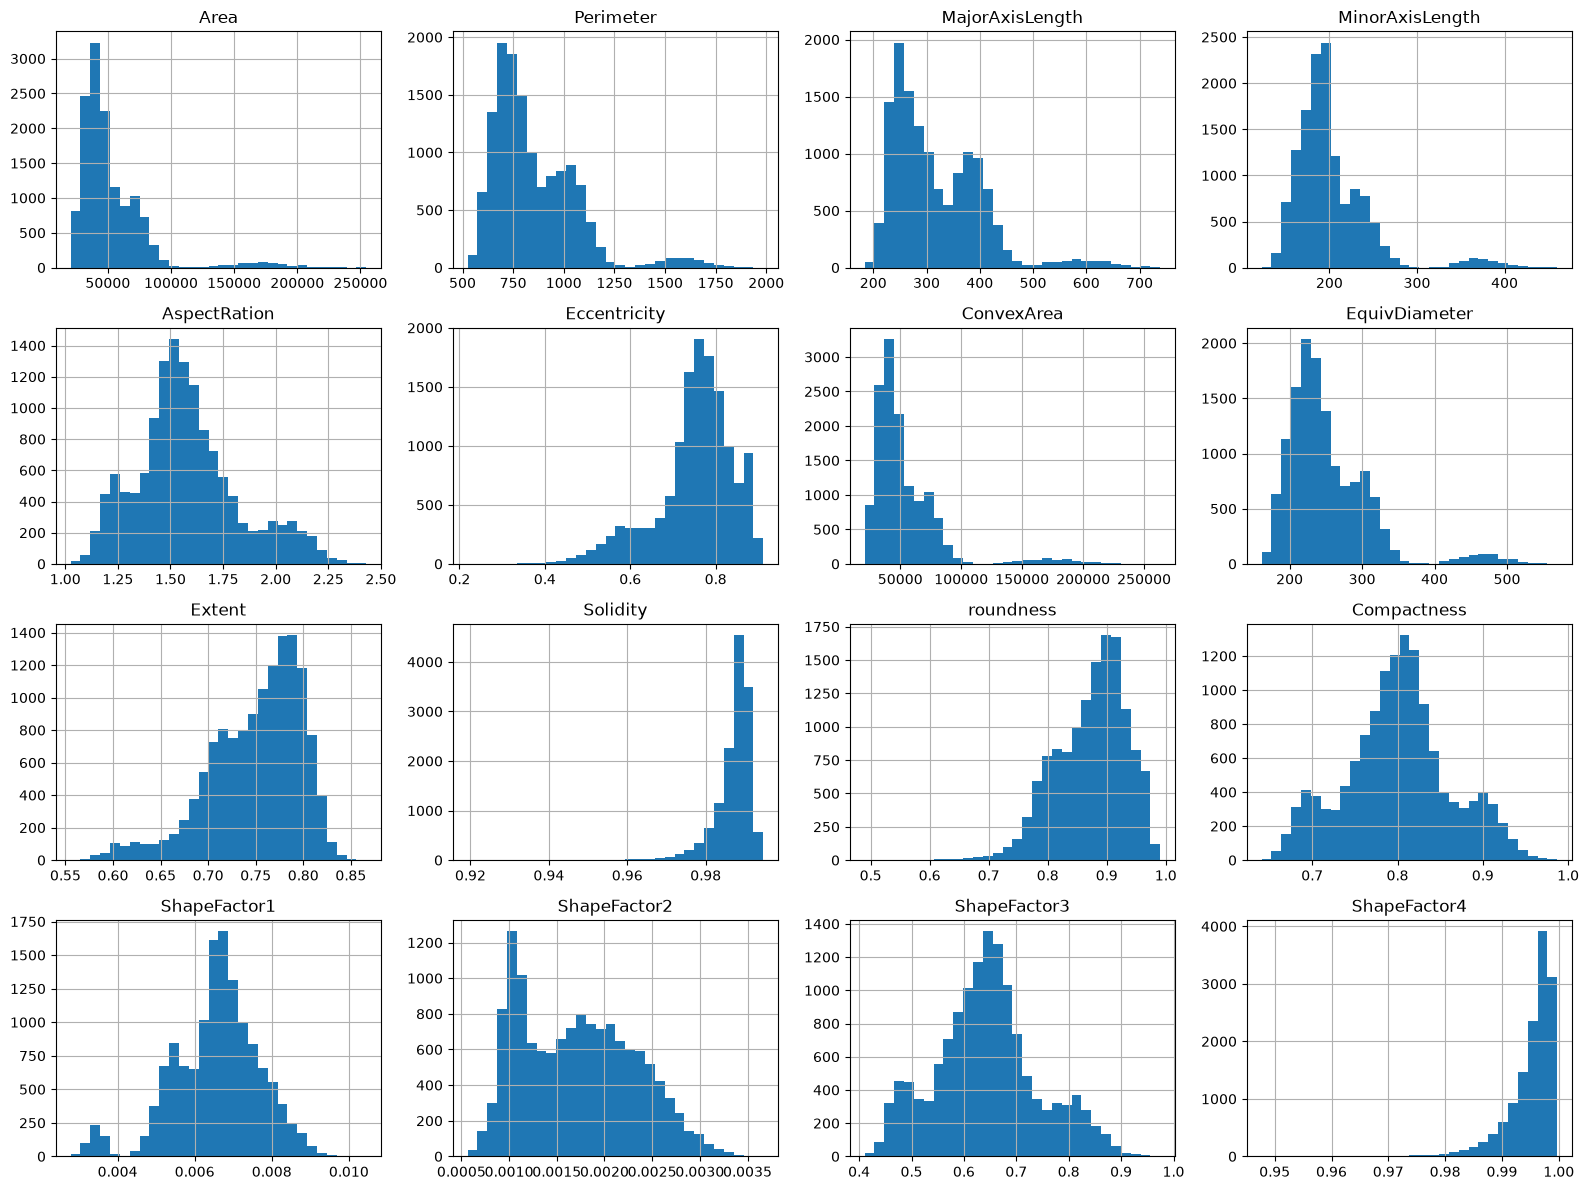

In [ ]:
df.hist(figsize=(16, 12), bins=30)
plt.tight_layout()
plt.show()

# The purpose of this is to understand how the values of each numerical feature are distributed in dataset.

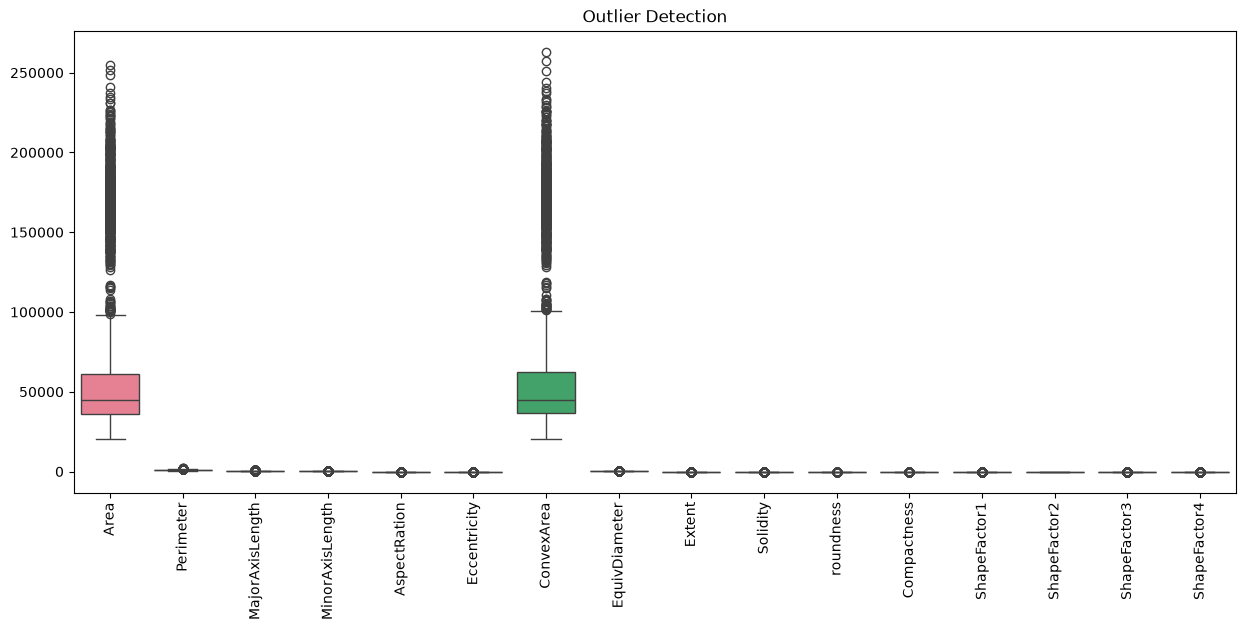

In [19]:
# Outlier Detection

plt.figure(figsize=(15, 6))

sns.boxplot(data=df.drop(columns="Class"))
plt.xticks(rotation=90)
plt.title("Outlier Detection")
plt.show()

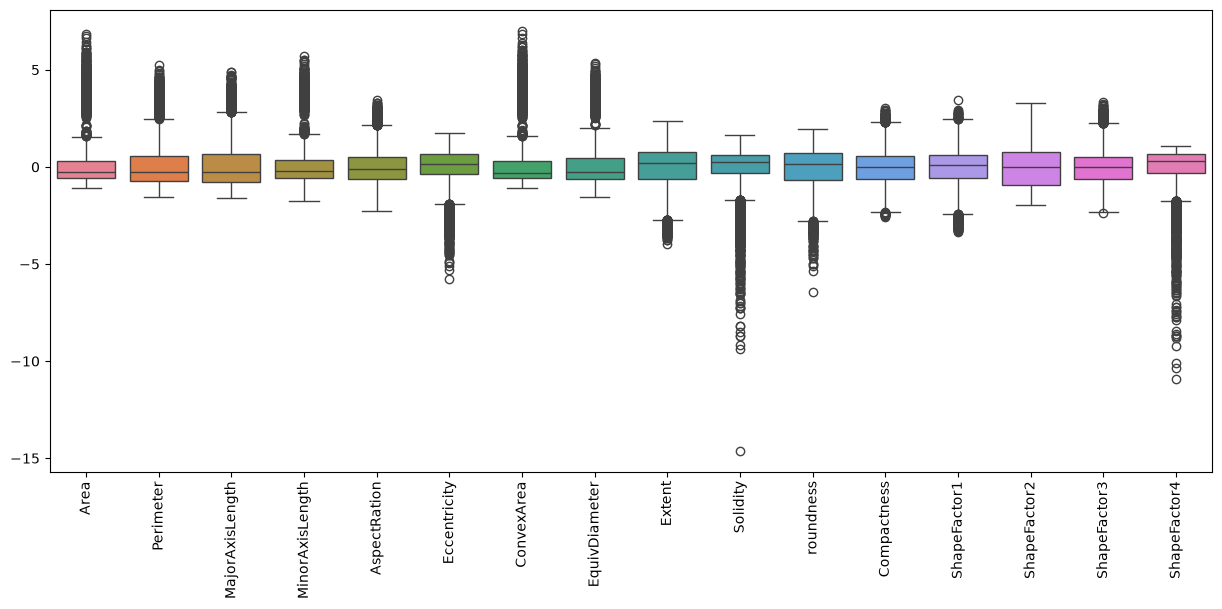

In [20]:
# Boxplot after Standardizing 

scaled_df = pd.DataFrame(
    StandardScaler().fit_transform(df.drop(columns="Class")),
    columns=df.drop(columns="Class").columns
)

plt.figure(figsize=(15, 6))
sns.boxplot(data=scaled_df)
plt.xticks(rotation=90)
plt.show()

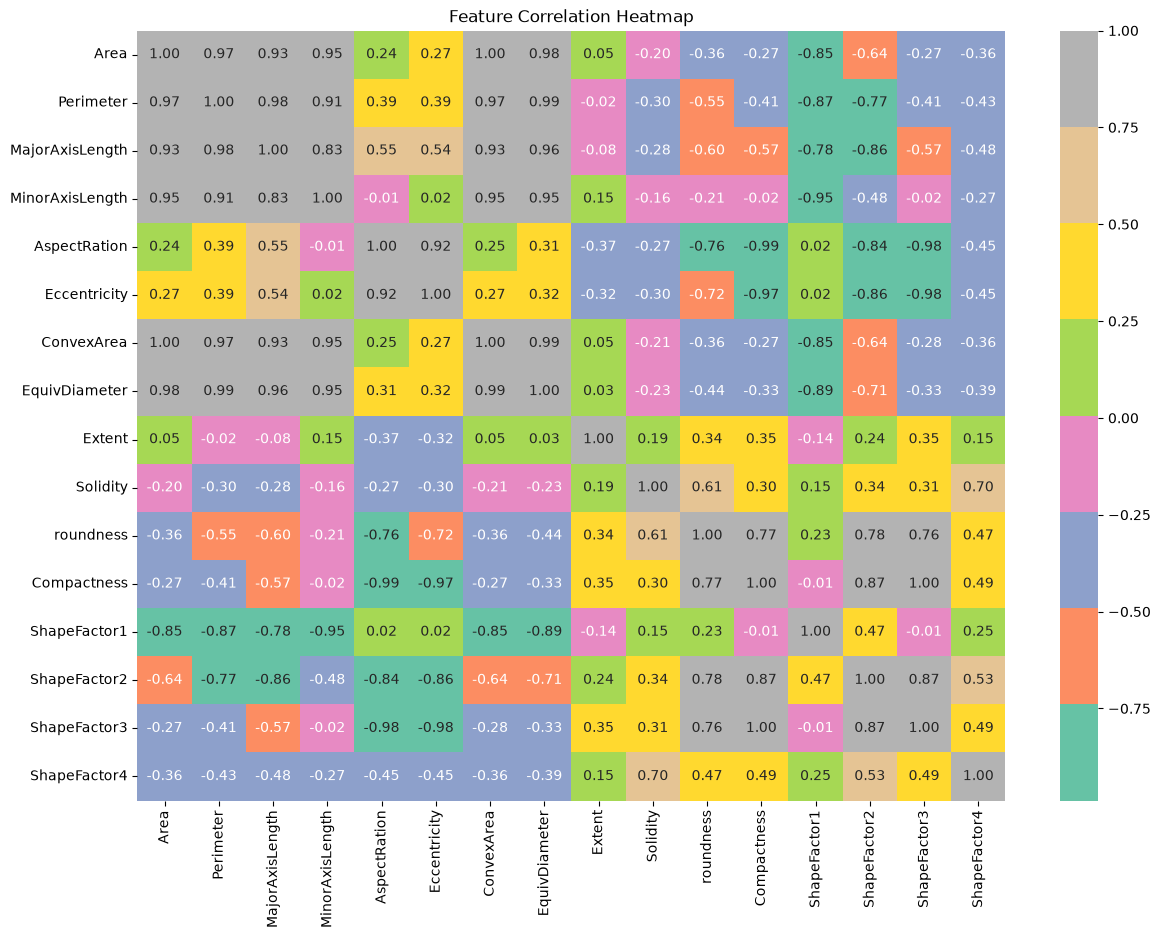

In [22]:
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.drop(columns="Class").corr(),
    annot=True,
    fmt=".2f",
    cmap="Set2"
)

plt.title("Feature Correlation Heatmap")
plt.show()

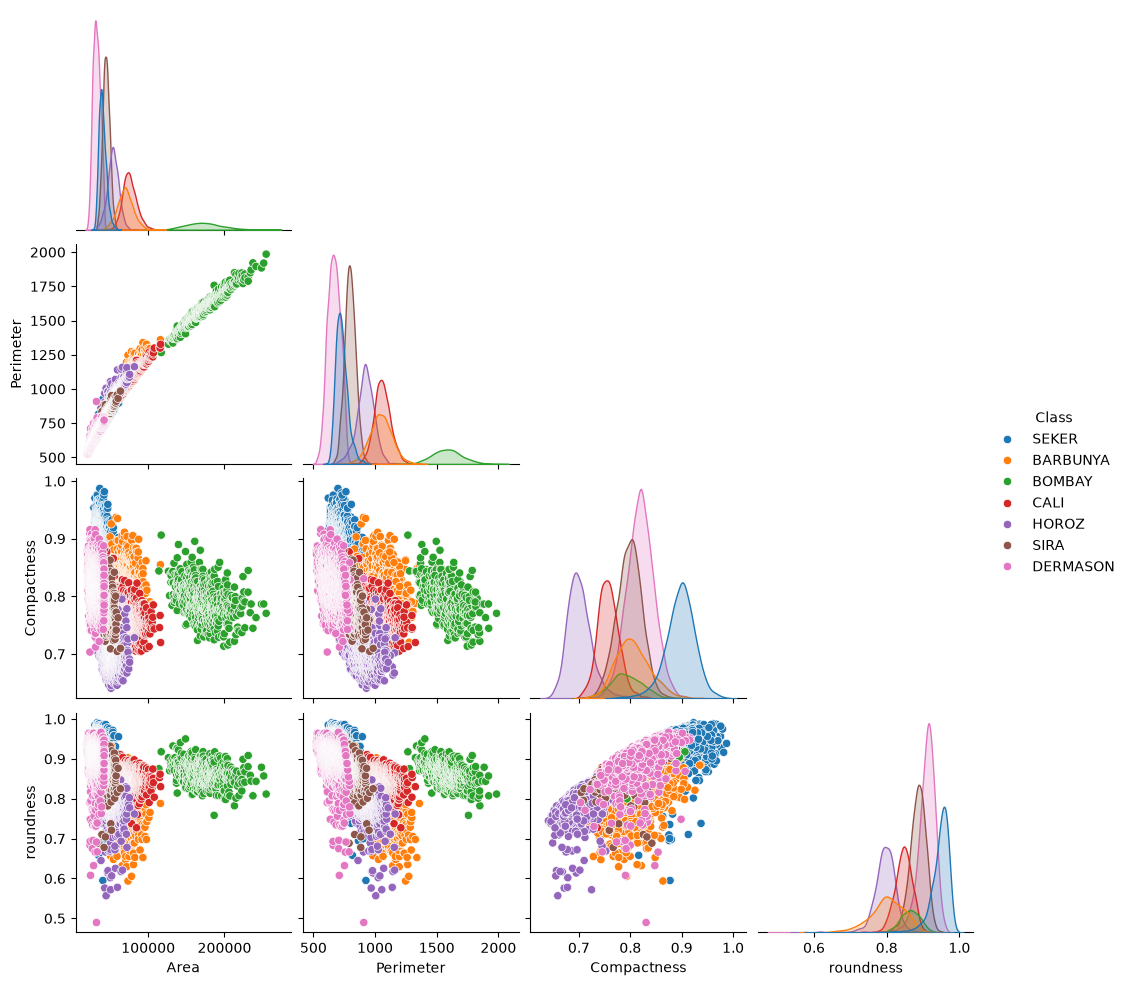

In [23]:
sns.pairplot(
    df,
    vars=["Area", "Perimeter", "Compactness", "roundness"],
    hue="Class",
    corner=True
)

plt.show()

In [24]:
skewness = df.drop(columns="Class").skew()

print(skewness.sort_values(ascending=False))

Area               2.947136
ConvexArea         2.936102
MinorAxisLength    2.232013
EquivDiameter      1.947303
Perimeter          1.628018
MajorAxisLength    1.365813
AspectRation       0.589045
ShapeFactor2       0.294332
ShapeFactor3       0.242767
Compactness        0.036309
ShapeFactor1      -0.530427
roundness         -0.648725
Extent            -0.895655
Eccentricity      -1.064932
Solidity          -2.546877
ShapeFactor4      -2.760125
dtype: float64


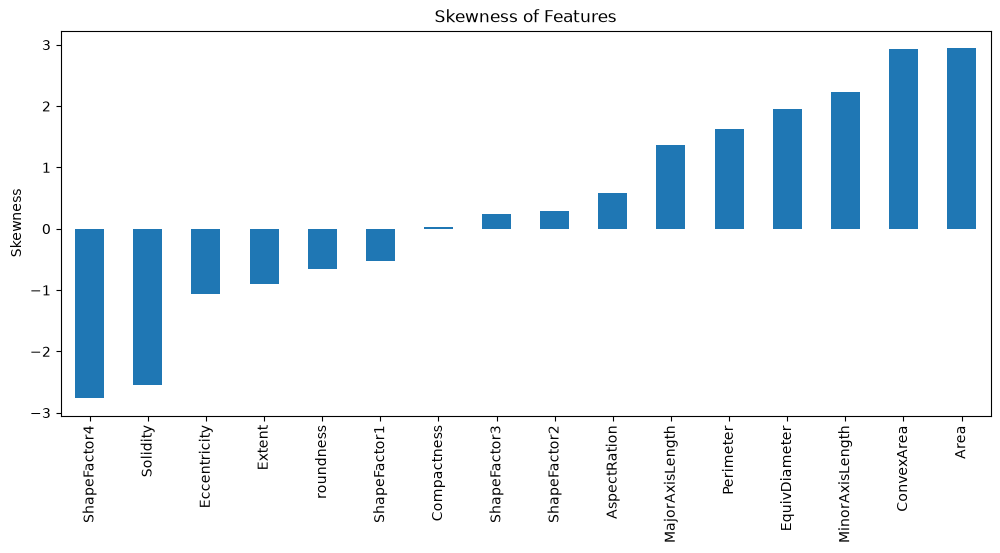

In [25]:
plt.figure(figsize=(12, 5))
skewness.sort_values().plot(kind="bar")
plt.title("Skewness of Features")
plt.ylabel("Skewness")
plt.show()

In [26]:
X = df.drop(columns="Class")
y = df["Class"]

In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [28]:
# Outlier treatment

Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = (X_train < lower) | (X_train > upper)

print(outliers.sum())

Area               443
Perimeter          405
MajorAxisLength    307
MinorAxisLength    457
AspectRation       403
Eccentricity       684
ConvexArea         442
EquivDiameter      422
Extent             208
Solidity           621
roundness           67
Compactness        108
ShapeFactor1       428
ShapeFactor2         0
ShapeFactor3       164
ShapeFactor4       616
dtype: int64


In [29]:
X_train_clip = X_train.clip(lower, upper, axis=1)
X_test_clip = X_test.clip(lower, upper, axis=1)

In [31]:
# Use PowerTransformer to reduce skewness.

from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer(method="yeo-johnson")

X_train_power = pt.fit_transform(X_train)
X_test_power = pt.transform(X_test)

print("Skewness before:")
print(X_train.skew())

print("\nSkewness after:")
print(pd.DataFrame(X_train_power, columns=X.columns).skew())

Skewness before:
Area               2.936712
Perimeter          1.624442
MajorAxisLength    1.355629
MinorAxisLength    2.240298
AspectRation       0.590116
Eccentricity      -1.067477
ConvexArea         2.924108
EquivDiameter      1.944595
Extent            -0.884394
Solidity          -2.642263
roundness         -0.629487
Compactness        0.035567
ShapeFactor1      -0.535045
ShapeFactor2       0.296287
ShapeFactor3       0.242416
ShapeFactor4      -2.824889
dtype: float64

Skewness after:
Area               0.030078
Perimeter          0.063175
MajorAxisLength    0.077055
MinorAxisLength   -0.004338
AspectRation       0.008700
Eccentricity      -0.060506
ConvexArea         0.032636
EquivDiameter      0.030288
Extent            -0.085851
Solidity          -0.967458
roundness         -0.057949
Compactness       -0.001419
ShapeFactor1       0.012193
ShapeFactor2       0.056581
ShapeFactor3       0.002131
ShapeFactor4      -1.292766
dtype: float64


In [ ]:


from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def preprocess(train, valid, method):

    train = train.copy()
    valid = valid.copy()

    if method == "Clip + Power":
        q1 = train.quantile(0.25)
        q3 = train.quantile(0.75)
        iqr = q3 - q1

        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr

        train = train.clip(lower, upper, axis=1)
        valid = valid.clip(lower, upper, axis=1)

    if method in ["Power", "Clip + Power"]:
        scaler = PowerTransformer()
    else:
        scaler = StandardScaler()

    train = scaler.fit_transform(train)
    valid = scaler.transform(valid)

    return train, valid

In [33]:
methods = ["Standard", "Power", "Clip + Power"]
scores_list = []

for method in methods:
    scores = []

    for tr, val in cv.split(X_train, y_train):
        x1, x2 = preprocess(
            X_train.iloc[tr], X_train.iloc[val], method
        )

        model = SVC(C=10)
        model.fit(x1, y_train.iloc[tr])

        scores.append(
            accuracy_score(y_train.iloc[val], model.predict(x2))
        )

    scores_list.append([method, np.mean(scores)])

preprocessing_df = pd.DataFrame(
    scores_list, columns=["Method", "CV Accuracy"]
)

print(preprocessing_df)

         Method  CV Accuracy
0      Standard     0.932620
1         Power     0.933727
2  Clip + Power     0.933174


In [34]:
best_method = preprocessing_df.loc[
    preprocessing_df["CV Accuracy"].idxmax(), "Method"
]

print("Best Method:", best_method)

Best Method: Power


In [35]:
from sklearn.preprocessing import StandardScaler, PowerTransformer

X_train_final = X_train.copy()
X_test_final = X_test.copy()

if best_method == "Clip + Power":
    q1 = X_train_final.quantile(0.25)
    q3 = X_train_final.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    X_train_final = X_train_final.clip(lower, upper, axis=1)
    X_test_final = X_test_final.clip(lower, upper, axis=1)

if best_method in ["Power", "Clip + Power"]:
    scaler = PowerTransformer()
else:
    scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_final)
X_test_scaled = scaler.transform(X_test_final)

In [36]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import HistGradientBoostingClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=9),
    "SVM": SVC(C=10),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42)
}

In [37]:
from sklearn.metrics import accuracy_score, f1_score

results = []

for name, model in models.items():

    model.fit(X_train_scaled, y_train)

    train_pred = model.predict(X_train_scaled)
    test_pred = model.predict(X_test_scaled)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    results.append([
        name,
        train_acc,
        test_acc,
        f1_score(y_test, test_pred, average="macro"),
        "Yes" if train_acc - test_acc > 0.05 else "No"
    ])

comparison = pd.DataFrame(
    results,
    columns=["Model", "Train Accuracy", "Test Accuracy", "F1 Score", "Overfitting"]
)

print(comparison.sort_values("Test Accuracy", ascending=False))

                 Model  Train Accuracy  Test Accuracy  F1 Score Overfitting
5                  SVM        0.941296       0.924695  0.936065          No
0  Logistic Regression        0.927543       0.919158  0.930119          No
3          Extra Trees        0.993262       0.918051  0.930138         Yes
7    Gradient Boosting        0.987539       0.918051  0.930284         Yes
4                  KNN        0.936589       0.916574  0.927914          No
2        Random Forest        0.987632       0.915467  0.927058         Yes
1        Decision Tree        0.979970       0.899963  0.915010         Yes
6          Naive Bayes        0.894314       0.897379  0.907777          No


In [38]:
from sklearn.base import clone

cv_results = []

for name, model in models.items():
    scores = []

    for tr, val in cv.split(X_train, y_train):
        x1, x2 = preprocess(
            X_train.iloc[tr], X_train.iloc[val], best_method
        )

        m = clone(model)
        m.fit(x1, y_train.iloc[tr])

        scores.append(m.score(x2, y_train.iloc[val]))

    cv_results.append([name, np.mean(scores)])

cv_df = pd.DataFrame(
    cv_results, columns=["Model", "CV Accuracy"]
).sort_values("CV Accuracy", ascending=False)

print(cv_df)

best_name = cv_df.iloc[0]["Model"]
print("Best Model:", best_name)

                 Model  CV Accuracy
5                  SVM     0.933727
7    Gradient Boosting     0.929482
0  Logistic Regression     0.926436
4                  KNN     0.924682
2        Random Forest     0.923852
3          Extra Trees     0.922006
1        Decision Tree     0.901699
6          Naive Bayes     0.893853
Best Model: SVM


In [39]:
from sklearn.model_selection import ParameterGrid

params = {
    "SVM": {"C": [1, 10, 50], "gamma": ["scale", 0.01, 0.1]},
    "KNN": {"n_neighbors": [5, 9, 15]},
    "Random Forest": {"max_depth": [15, None], "min_samples_leaf": [1, 2]},
    "Extra Trees": {"max_depth": [15, None], "min_samples_leaf": [1, 2]},
    "Decision Tree": {"max_depth": [8, 12, 16]},
    "Logistic Regression": {"C": [0.1, 1, 10]},
    "Naive Bayes": {"var_smoothing": [1e-9, 1e-8]},
    "Gradient Boosting": {"max_leaf_nodes": [15, 31]}
}

best_score = 0
best_params = {}

for p in ParameterGrid(params[best_name]):
    scores = []

    for tr, val in cv.split(X_train, y_train):
        x1, x2 = preprocess(
            X_train.iloc[tr], X_train.iloc[val], best_method
        )

        model = clone(models[best_name])
        model.set_params(**p)
        model.fit(x1, y_train.iloc[tr])

        scores.append(model.score(x2, y_train.iloc[val]))

    if np.mean(scores) > best_score:
        best_score = np.mean(scores)
        best_params = p

print("Best Parameters:", best_params)
print("Best CV Accuracy:", best_score)

Best Parameters: {'C': 50, 'gamma': 0.01}
Best CV Accuracy: 0.9337276046600117


In [40]:
selector = ExtraTreesClassifier(
    n_estimators=200, random_state=42
)

selector.fit(X_train, y_train)

importance = pd.Series(
    selector.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)

ShapeFactor3       0.083043
ShapeFactor1       0.082547
Perimeter          0.077182
MajorAxisLength    0.076987
Compactness        0.074945
AspectRation       0.072588
EquivDiameter      0.072541
Eccentricity       0.070641
MinorAxisLength    0.067588
ShapeFactor2       0.067428
ConvexArea         0.066839
Area               0.065821
roundness          0.063410
ShapeFactor4       0.026977
Solidity           0.017938
Extent             0.013524
dtype: float64


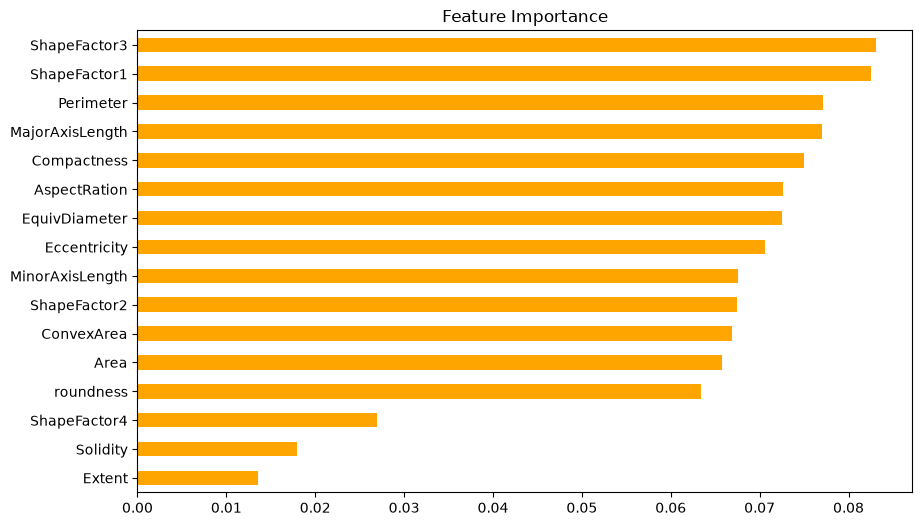

In [45]:
importance.sort_values().plot(kind="barh", figsize=(10, 6),color='orange')
plt.title("Feature Importance")
plt.show()

In [46]:
feature_results = []

for n in [6, 8, 10, 12, 16]:
    scores = []

    for tr, val in cv.split(X_train, y_train):
        x_tr = X_train.iloc[tr]
        x_val = X_train.iloc[val]

        fs = ExtraTreesClassifier(
            n_estimators=200, random_state=42
        )
        fs.fit(x_tr, y_train.iloc[tr])

        ranking = pd.Series(
            fs.feature_importances_,
            index=X.columns
        ).sort_values(ascending=False)

        features = ranking.head(n).index.tolist()

        x1, x2 = preprocess(
            x_tr[features], x_val[features], best_method
        )

        model = clone(models[best_name])
        model.set_params(**best_params)
        model.fit(x1, y_train.iloc[tr])

        scores.append(model.score(x2, y_train.iloc[val]))

    feature_results.append([n, np.mean(scores)])

feature_df = pd.DataFrame(
    feature_results, columns=["Features", "CV Accuracy"]
)

print(feature_df)

   Features  CV Accuracy
0         6     0.914067
1         8     0.914898
2        10     0.915083
3        12     0.917390
4        16     0.933728


In [47]:
best_cv = feature_df["CV Accuracy"].max()

best_n = int(feature_df.loc[
    feature_df["CV Accuracy"] >= best_cv - 0.005,
    "Features"
].min())

selected_features = importance.head(best_n).index.tolist()

print("Selected Features:", selected_features)

Selected Features: ['ShapeFactor3', 'ShapeFactor1', 'Perimeter', 'MajorAxisLength', 'Compactness', 'AspectRation', 'EquivDiameter', 'Eccentricity', 'MinorAxisLength', 'ShapeFactor2', 'ConvexArea', 'Area', 'roundness', 'ShapeFactor4', 'Solidity', 'Extent']


In [52]:
!pip install imbalanced-learn

  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
Using cached imbalanced_learn-0.14.2-py3-none-any.whl (236 kB)
Using cached sklearn_compat-0.1.6-py3-none-any.whl (22 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [imbalanced-learn]

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [53]:
from imblearn.over_sampling import SMOTE

normal_scores = []
smote_scores = []

for tr, val in cv.split(X_train, y_train):

    x1, x2 = preprocess(
        X_train.iloc[tr][selected_features],
        X_train.iloc[val][selected_features],
        best_method
    )

    y1 = y_train.iloc[tr]
    y2 = y_train.iloc[val]

    normal = clone(models[best_name])
    normal.set_params(**best_params)
    normal.fit(x1, y1)

    normal_scores.append(
        f1_score(y2, normal.predict(x2), average="macro")
    )

    x_res, y_res = SMOTE(random_state=42).fit_resample(x1, y1)

    balanced = clone(models[best_name])
    balanced.set_params(**best_params)
    balanced.fit(x_res, y_res)

    smote_scores.append(
        f1_score(y2, balanced.predict(x2), average="macro")
    )

print("Normal F1:", np.mean(normal_scores))
print("SMOTE F1:", np.mean(smote_scores))

Normal F1: 0.9450466834882965
SMOTE F1: 0.943136609584364


In [54]:
X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()

if best_method == "Clip + Power":
    q1 = X_train_selected.quantile(0.25)
    q3 = X_train_selected.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    X_train_selected = X_train_selected.clip(lower, upper, axis=1)
    X_test_selected = X_test_selected.clip(lower, upper, axis=1)

if best_method in ["Power", "Clip + Power"]:
    scaler = PowerTransformer()
else:
    scaler = StandardScaler()

X_train_ready = scaler.fit_transform(X_train_selected)
X_test_ready = scaler.transform(X_test_selected)

final_model = clone(models[best_name])
final_model.set_params(**best_params)

use_smote = np.mean(smote_scores) > np.mean(normal_scores)

if use_smote:
    X_fit, y_fit = SMOTE(random_state=42).fit_resample(
        X_train_ready, y_train
    )
else:
    X_fit, y_fit = X_train_ready, y_train

final_model.fit(X_fit, y_fit)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",50
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",0.01
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [55]:
from sklearn.metrics import classification_report, confusion_matrix

train_pred = final_model.predict(X_train_ready)
test_pred = final_model.predict(X_test_ready)

print("Training Accuracy:", accuracy_score(y_train, train_pred))
print("Testing Accuracy:", accuracy_score(y_test, test_pred))


print("\nClassification Report:")
print(classification_report(y_test, test_pred))

Training Accuracy: 0.9368654236662359
Testing Accuracy: 0.9243263196751569

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.92      0.91      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.93       326
    DERMASON       0.92      0.92      0.92       709
       HOROZ       0.97      0.94      0.96       372
       SEKER       0.95      0.96      0.95       406
        SIRA       0.87      0.87      0.87       527

    accuracy                           0.92      2709
   macro avg       0.94      0.93      0.94      2709
weighted avg       0.92      0.92      0.92      2709



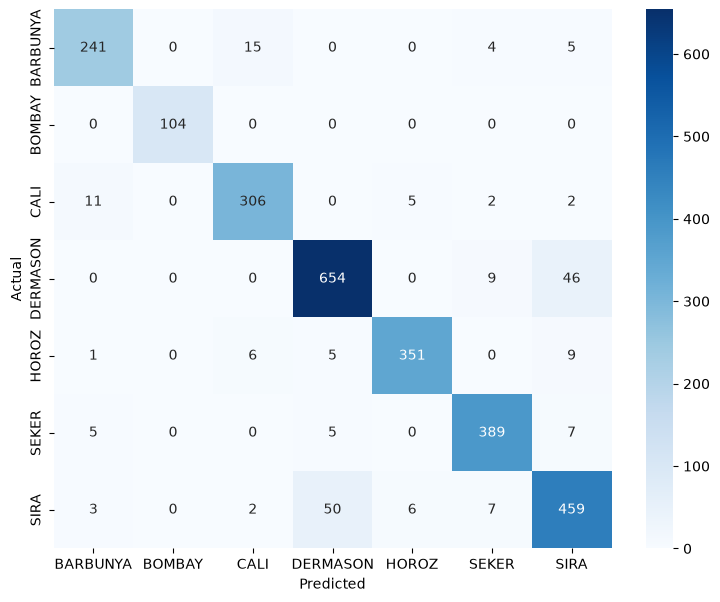

In [56]:
cm = confusion_matrix(
    y_test, test_pred, labels=final_model.classes_
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=final_model.classes_,
    yticklabels=final_model.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [57]:
import joblib

joblib.dump(final_model, "beans_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(selected_features, "selected_features.pkl")
joblib.dump(best_method, "preprocessing_method.pkl")

if best_method == "Clip + Power":
    joblib.dump((lower, upper), "outlier_bounds.pkl")

print("Model and preprocessing files saved!")

Model and preprocessing files saved!


In [58]:
from sklearn.ensemble import VotingClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score


In [59]:
voting_model = VotingClassifier(
    estimators=[
        ("svm", SVC(C=10, probability=True, random_state=42)),
        ("rf", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=2, random_state=42
        )),
        ("et", ExtraTreesClassifier(
            n_estimators=200, min_samples_leaf=2, random_state=42
        )),
        ("lr", LogisticRegression(max_iter=2000))
    ],
    voting="soft",
    n_jobs=-1
)

In [60]:
voting_model.fit(X_train_scaled, y_train)

train_pred = voting_model.predict(X_train_scaled)
test_pred = voting_model.predict(X_test_scaled)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, test_pred))

print("Macro F1:",
      f1_score(y_test, test_pred, average="macro"))

/Users/rehan/Desktop/Crop_Yield/.myenv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Training Accuracy: 0.9624330810411666
Testing Accuracy: 0.9246954595791805
Macro F1: 0.9357114369069741


In [61]:
from sklearn.ensemble import StackingClassifier

stacking_model = StackingClassifier(
    estimators=[
        ("svm", SVC(C=10, probability=True)),
        ("rf", RandomForestClassifier(
            n_estimators=200, min_samples_leaf=2, random_state=42
        )),
        ("et", ExtraTreesClassifier(
            n_estimators=200, min_samples_leaf=2, random_state=42
        ))
    ],
    final_estimator=LogisticRegression(max_iter=2000),
    cv=5,
    n_jobs=-1
)

In [62]:
stacking_model.fit(X_train_scaled, y_train)

train_pred_stack = stacking_model.predict(X_train_scaled)
test_pred_stack = stacking_model.predict(X_test_scaled)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred_stack))

print("Testing Accuracy:",
      accuracy_score(y_test, test_pred_stack))

print("Macro F1:",
      f1_score(y_test, test_pred_stack, average="macro"))

/Users/rehan/Desktop/Crop_Yield/.myenv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/Users/rehan/Desktop/Crop_Yield/.myenv/lib/python3.14/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Training Accuracy: 0.969078825918405
Testing Accuracy: 0.926172019195275
Macro F1: 0.937522877448857


In [63]:
comparison_ensemble = pd.DataFrame({
    "Model": ["Soft Voting", "Stacking"],
    "Train Accuracy": [
        voting_model.score(X_train_scaled, y_train),
        stacking_model.score(X_train_scaled, y_train)
    ],
    "Test Accuracy": [
        voting_model.score(X_test_scaled, y_test),
        stacking_model.score(X_test_scaled, y_test)
    ]
})

print(comparison_ensemble)

         Model  Train Accuracy  Test Accuracy
0  Soft Voting        0.962433       0.924695
1     Stacking        0.969079       0.926172


In [66]:
from sklearn.metrics import accuracy_score, f1_score

candidates = {
    "Final Tuned Model": final_model,
    "Soft Voting": voting_model,
    "Stacking": stacking_model
}

for name, model in candidates.items():
    print("\n", name)
    print("Train Accuracy:", round(model.score(X_train_ready, y_train) * 100, 2))
    print("Test Accuracy:", round(model.score(X_test_ready, y_test) * 100, 2))
    print("Macro F1:", round(
        f1_score(y_test, model.predict(X_test_ready), average="macro") * 100, 2
    ))


 Final Tuned Model
Train Accuracy: 93.69
Test Accuracy: 92.43
Macro F1: 93.55

 Soft Voting
Train Accuracy: 37.23
Test Accuracy: 36.95
Macro F1: 20.66

 Stacking
Train Accuracy: 29.5
Test Accuracy: 29.72
Macro F1: 20.46


In [67]:
print("Full features:", X_train_scaled.shape)
print("Selected features:", X_train_ready.shape)

print("Voting expected:", voting_model.n_features_in_)
print("Stacking expected:", stacking_model.n_features_in_)

Full features: (10834, 16)
Selected features: (10834, 16)
Voting expected: 16
Stacking expected: 16


In [68]:
print("Soft Voting:",
      voting_model.score(X_test_scaled, y_test))

print("Stacking:",
      stacking_model.score(X_test_scaled, y_test))

Soft Voting: 0.9246954595791805
Stacking: 0.926172019195275
